## Lab: Network Analysis
#### Anna G. Castillo

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
%matplotlib inline

#### 1. Data Import and Preparation:
1.1. Import the first data set into a dataframe titled dfNode and the second data set into a dataframe titled dfEdge. \
1.2. Notice that some of the rows in the dfEdge table are duplicated. Duplication counts indicate how many times the same character pair (Character1 and Character2) have appeared together in certain comic books. Transform dfEdge in a way that each row shows a unique character pair along with the number of duplication count for each pair. In addition, rename the columns as: {'Character1':'from','Character2':'to','duplication count':'weight'} \
        Hint: You can consider using groupby with the size() method. The output should look similar to the screenshot below. 

In [2]:
dfNode = pd.read_csv("marvel_characters_combined.csv")
dfEdge = pd.read_csv("ID_co-occurrence.csv")
print(dfNode.shape)
print(dfEdge.shape)
print(dfNode["Universe"].value_counts())
dfNode.head()

(57, 3)
(6180, 2)
Universe
x-men       30
avengers    27
Name: count, dtype: int64


,ID,Label,Universe
0,1009504,Professor X,x-men
1,1009257,Cyclops,x-men
2,1009362,Iceman,x-men
3,1009159,Archangel,x-men
4,1009175,Beast,x-men


In [3]:
print(dfEdge.duplicated().sum())
dfEdge.head()

5346


,Character1,Character2
0,1009159,1009163
1,1009159,1009163
2,1009159,1009168
3,1009159,1009168
4,1009159,1009168


In [4]:
dfEdge = dfEdge.groupby(["Character1", "Character2"]).size().reset_index(name="duplication count")
dfEdge = dfEdge.rename(columns={"Character1": "from", "Character2": "to", "duplication count": "weight"})
print(dfEdge.shape)
dfEdge.head()

(834, 3)


,from,to,weight
0,1009159,1009163,2
1,1009159,1009168,12
2,1009159,1009175,26
3,1009159,1009182,14
4,1009159,1009219,6


#### 2. Pre-processing:
   2.1. Add a new column to dfNode called “color”, where x-men characters have the value of “blue” and avengers’ characters have the value of “red”. 

In [5]:
dfNode["color"] = dfNode["Universe"].map({"x-men": "blue", "avengers": "red"})
print(dfNode["color"].value_counts())
dfNode.head()

color
blue    30
red     27
Name: count, dtype: int64


,ID,Label,Universe,color
0,1009504,Professor X,x-men,blue
1,1009257,Cyclops,x-men,blue
2,1009362,Iceman,x-men,blue
3,1009159,Archangel,x-men,blue
4,1009175,Beast,x-men,blue


2.2. Update dfEdge so that it displays the name of each character instead of their ID. The character name that corresponds to each ID is shown in the dfNode table. In addition, add the universe information for both “from” and “to” values into dfEdge as two separate columns. 

Hint: There are various ways to complete this data pre-processing task (e.g., apply method, mapping, looping, merging/joining, etc.) The output should look similar to the screenshot below. 

In [6]:
names = dict(zip(dfNode["ID"], dfNode["Label"]))
universes = dict(zip(dfNode["ID"], dfNode["Universe"]))

dfEdge["fromUniverse"] = dfEdge["from"].map(universes)
dfEdge["toUniverse"] = dfEdge["to"].map(universes)
dfEdge["from"] = dfEdge["from"].map(names)
dfEdge["to"] = dfEdge["to"].map(names)
print(dfEdge.isna().sum())
dfEdge.head()

from            0
to              0
weight          0
fromUniverse    0
toUniverse      0
dtype: int64


,from,to,weight,fromUniverse,toUniverse
0,Archangel,Aurora,2,x-men,x-men
1,Archangel,Banshee,12,x-men,x-men
2,Archangel,Beast,26,x-men,x-men
3,Archangel,Bishop,14,x-men,x-men
4,Archangel,Cannonball,6,x-men,x-men


2.3. Let’s assume that we are only interested in comic books that had a cross-over between the two comic universes (x-men vs. avengers). Subset the dfEdge data so that it only includes entries where “fromUniverse” and “toUniverse” values are different from each other. The output should look as follows: 

In [7]:
dfEdge = dfEdge[dfEdge["fromUniverse"] != dfEdge["toUniverse"]]
print(dfEdge.shape)
dfEdge.head()

(286, 5)


,from,to,weight,fromUniverse,toUniverse
5,Archangel,Captain America,4,x-men,avengers
12,Archangel,Galactus,2,x-men,avengers
16,Archangel,Hercules,2,x-men,avengers
17,Archangel,Hulk,4,x-men,avengers
19,Archangel,Iron Man,2,x-men,avengers


#### 3. Graph Generation and Visualization: Now we will generate a directed network graph model using the Networkx package. First, please go over the documentation of the package on: https://networkx.org/documentation/stable/tutorial.html  Graphs in Networkx are stored as data objects and there are various ways to create a graph. Considering that we already have an Edge List dataframe (dfEdge), we can simply use the “.from_pandas_edgelist()” method to read the table as a graph, where each row in dfEdge corresponds to a specific edge between the two characters (characters are the nodes and their co-occurrence in cross-over books are the edges).   \
3.1. Import the networkx package and generate the edge list graph while storing all the information in dfEdge as edge attributes. For configuration of the method and parameter specifics, see the following: https://networkx.org/documentation/stable/reference/generated/networkx.convert_matrix.from_pand as_edgelist.html#networkx.convert_matrix.from_pandas_edgelist \
3.2. Use the drawing functionality of Networkx to generate a visualization of the graph (https://networkx.org/documentation/stable/reference/drawing.html). 

In [8]:
G = nx.from_pandas_edgelist(dfEdge, source="from", target="to", edge_attr=True, create_using=nx.DiGraph())
print(G.number_of_nodes())
print(G.number_of_edges())
print(list(G.edges(data=True))[:3])

53
286
[('Archangel', 'Captain America', {'weight': 4, 'fromUniverse': 'x-men', 'toUniverse': 'avengers'}), ('Archangel', 'Galactus', {'weight': 2, 'fromUniverse': 'x-men', 'toUniverse': 'avengers'}), ('Archangel', 'Hercules', {'weight': 2, 'fromUniverse': 'x-men', 'toUniverse': 'avengers'})]


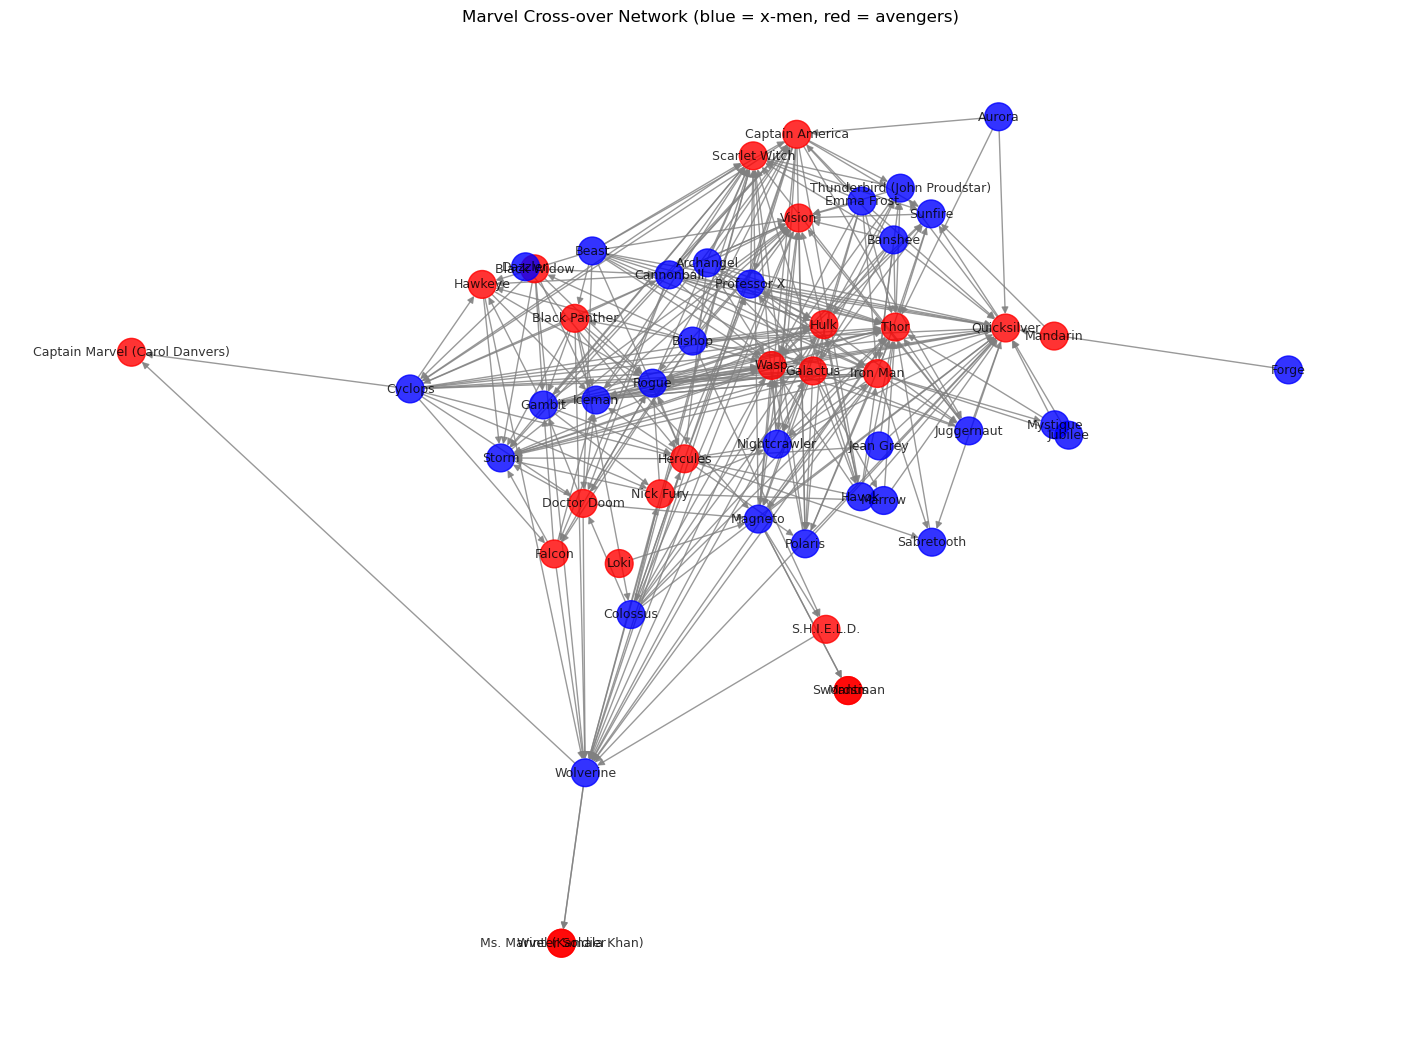

In [9]:
colors = dict(zip(dfNode["Label"], dfNode["color"]))
nodeColors = [colors[node] for node in G.nodes()]

fig = plt.figure(figsize=(14, 10))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, node_color=nodeColors, with_labels=True, node_size=400, font_size=9, edge_color="gray", alpha=0.8)
plt.title("Marvel Cross-over Network (blue = x-men, red = avengers)")
plt.show()

#### QUESTION: Provide the network graph.  
You are free to experiment with different layouts and visualization options. Below, I am using the KamadaKawai layout with each node colored based on the color information in dfNode (from Step 2.1). 

The network graph is shown above. I used the Kamada-Kawai layout and colored the nodes with the color column from dfNode (blue = x-men, red = avengers). Most characters are packed into the center because they appear with many characters from the other universe, while characters like Forge, Captain Marvel and Winter Soldier sit on the outside with only a few cross-over links.

### 4. Metric-based Analysis: 
The final task of the lab is to compute some of the well-known network metrics. Note that most of these values can be simply obtained by invoking the relevant method(s) on the graph object that you created in Step 3.1.

#### QUESTION: Obtain the following values for the network: • Network density • TOP 5 nodes (characters) with the highest degree centrality • TOP 5 nodes (characters) with the highest closeness centrality • The distance (i.e., shortest path) between “Winter Soldier” and “Magneto” 

In [10]:
print("Density:", nx.density(G))

Density: 0.10377358490566038


In [11]:
degree = pd.Series(nx.degree_centrality(G)).sort_values(ascending=False)
print(degree.head(5))

Quicksilver        0.538462
Thor               0.500000
Iron Man           0.461538
Captain America    0.423077
Hulk               0.403846
dtype: float64


In [12]:
closeness = pd.Series(nx.closeness_centrality(G)).sort_values(ascending=False)
print(closeness.head(5))

Thor           0.538462
Wolverine      0.537731
Vision         0.489879
Quicksilver    0.480769
Wasp           0.477318
dtype: float64


In [13]:
print(nx.has_path(G, "Winter Soldier", "Magneto"))
print(nx.has_path(G, "Magneto", "Winter Soldier"))
print(nx.shortest_path(G, "Magneto", "Winter Soldier"))
print(nx.shortest_path_length(G, "Magneto", "Winter Soldier"))

G2 = G.to_undirected()
print(nx.shortest_path(G2, "Winter Soldier", "Magneto"))
print(nx.shortest_path_length(G2, "Winter Soldier", "Magneto"))

False
True
['Magneto', 'Quicksilver', 'Wolverine', 'Winter Soldier']
3
['Winter Soldier', 'Wolverine', 'Captain America', 'Magneto']
3
